03 — Auto-encodeurs et détection d'anomalies (Partie 3)

Principe : **entraîner uniquement sur des feuilles saines**. L'auto-encodeur apprend à reconstruire « ce qu'est une feuille saine » ; une feuille malade (taches, jaunissement, déformations) est mal reconstruite → **erreur de reconstruction élevée = anomalie**. Aucune étiquette de maladie n'est utilisée pour l'entraînement : c'est de l'apprentissage **non supervisé**.

Plan : (1) AE convolutif 64×64 ; (2) influence de la dimension latente k ∈ {16, 64, 256} ; (3) variante débruiteuse ; (4) histogrammes et seuil (percentile 95 des saines de **validation**), évaluation **unique** sur le test : AUROC, rappel des maladies, fausses alarmes ; (5) analyse des échecs par maladie.



In [1]:
# === Configuration (Colab, Kaggle ou local) ===
ALLOW_CPU = False   # True seulement pour les notebooks sans entraînement (00 et 06)
REPO_URL = "https://github.com/fayelise/diagnoculture.git"   # utilisé sur Kaggle uniquement

import os, sys, subprocess
from pathlib import Path

# 1. Environnement. Colab est testé AVANT Kaggle : sur Colab, kagglehub peut créer /kaggle/input.
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
IN_KAGGLE = not IN_COLAB and "KAGGLE_KERNEL_RUN_TYPE" in os.environ

if IN_COLAB:
    # Projet sur Google Drive : résultats et checkpoints survivent aux déconnexions
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/diagnoculture")
    os.environ["DIAGNO_CACHE"] = "/content/cache"   # cache d'images sur le disque local de Colab (rapide)
    for name in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):   # jeton Kaggle (Secrets Colab)
        try:
            os.environ[name] = userdata.get(name)
        except Exception:
            pass
elif IN_KAGGLE:
    # Code cloné depuis GitHub ; résultats du notebook précédent (ajouté en Input) recopiés
    # dans /kaggle/working : l'Output de ce notebook contiendra donc toute la chaîne.
    import shutil
    ROOT = Path("/kaggle/working/diagnoculture")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    for inp in Path("/kaggle/input").iterdir():
        for prev in (inp / "results", inp / "diagnoculture" / "results"):
            if (prev / "00_split").is_dir():
                shutil.copytree(prev, ROOT / "results", dirs_exist_ok=True)
else:
    # Local : notebook lancé depuis notebooks/ ou depuis la racine du dépôt
    ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent

assert (ROOT / "src" / "utils.py").exists(), f"Projet introuvable dans {ROOT} (voir README, section Installation)"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# 2. Paquets absents des images Colab / Kaggle (en local : pip install -r requirements.txt)
if IN_COLAB or IN_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchinfo==1.8.0", "ImageHash==4.3.2",
                    "grad-cam==1.5.7", "onnx==1.23.2", "onnxruntime==1.29.0",
                    "umap-learn==0.5.12", "kagglehub==1.0.2"], check=True)

# 3. Configuration du projet
from src.utils import load_config, resolve_paths, set_seed, ensure_data, get_device, machine_info, TestGuard
cfg = load_config()
set_seed(cfg["seed"])
paths = resolve_paths(cfg)
DATA_ROOT = ensure_data(cfg)          # télécharge PlantVillage au 1er lancement de la session (hors Kaggle)
DEVICE = get_device()
guard = TestGuard(paths["results"])   # le test ne sert qu'une fois par modèle final
FORCE_TEST_RERUN = False              # True uniquement pour ré-exécuter à l'identique après une coupure
print("Projet :", ROOT, "| données :", DATA_ROOT, "| device :", DEVICE)
print(machine_info())

# 4. Garde-fou GPU : sur CPU, chaque epoch est 40 à 80 fois plus lente et le budget train.max_minutes
#    coupe les entraînements après 1 à 4 epochs (cause des résultats invalides de la 1re exécution).
#    DIAGNO_ALLOW_CPU=1 sert uniquement au test rapide du pipeline (README).
if DEVICE.type != "cuda" and not (ALLOW_CPU or os.environ.get("DIAGNO_ALLOW_CPU") == "1"):
    raise RuntimeError("Pas de GPU : Exécution → Modifier le type d'exécution → T4 GPU "
                       "(Kaggle : Session options → Accelerator → GPU T4).")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projet : /content/drive/MyDrive/diagnoculture | données : /kaggle/input/plantvillage-dataset/plantvillage dataset/color | device : cuda
{'env': 'colab', 'python': '3.13.16', 'torch': '2.11.0+cu130', 'cpu': 'x86_64', 'cpu_count': 2, 'gpu': 'Tesla T4'}


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score
from torchinfo import summary

from src.datasets import CLASSES, HEALTHY, TensorImageDataset, build_transform, get_split_tensors, make_loader
from src.metrics import anomaly_metrics, plot_roc
from src.models import ConvAutoencoder
from src.ood import fit_threshold
from src.train import fit_reconstruction, load_best, reconstruction_scores, record_experiment
from src.utils import load_json, save_json

P3 = cfg["part3"]
SIZE = cfg["resolution"]["ae"]
OUT = paths["results"] / "03_autoencoders"
OUT.mkdir(parents=True, exist_ok=True)
BS, NW = cfg["train"]["batch_size"], cfg["data"]["num_workers"]
H_IDX = CLASSES.index(HEALTHY)

data = get_split_tensors(paths, DATA_ROOT, SIZE)
tf_train, tf_eval = build_transform(True, augment="flip"), build_transform(False)   # pixels dans [0,1], pas de normalisation

def subset(split, healthy_only):
    df, x = data[split]
    mask = (df["label"] == H_IDX).to_numpy() if healthy_only else np.ones(len(df), bool)
    return df[mask].reset_index(drop=True), TensorImageDataset(x[torch.tensor(mask)], df["label"][mask],
                                                               tf_train if split == "train" else tf_eval)

_, ds_train_h = subset("train", True)      # apprentissage : saines uniquement
_, ds_val_h = subset("val", True)          # sélection de l'epoch : saines de validation
df_val, ds_val = subset("val", False)      # seuil / choix de k : validation complète
df_test, ds_test = subset("test", False)   # évaluation finale unique
new_train_loader = lambda: make_loader(ds_train_h, BS, True, NW, cfg["seed"])
val_h_loader = make_loader(ds_val_h, 256, False, NW)
val_loader = make_loader(ds_val, 256, False, NW)
assert len(ds_train_h) and len(ds_val_h), "Aucune feuille saine en train ou en validation : vérifier le split (notebook 00)"
print(f"Saines : train {len(ds_train_h)}, val {len(ds_val_h)} | validation complète {len(ds_val)} | test {len(ds_test)}")

Saines : train 1114, val 238 | validation complète 2722 | test 2726


1. Architecture

**Encodeur** : 4 convolutions $F=4$, $S=2$, $P=1$ → $O = (W-4+2)/2+1 = W/2$ : 64 → 32 → 16 → 8 → 4, canaux 32 → 64 → 128 → 256 ; puis Flatten (256·4·4 = 4096) → Linear → **code latent z de dimension k**.
Ici le pas S = 2 joue le rôle du pooling (sous-échantillonnage **appris**).

**Décodeur** (symétrique) : Linear k → 4096 → reshape 256×4×4 → 4 ConvTranspose2d ($F=4$, $S=2$, $P=1$ : sortie $= (W-1)·2 - 2 + 4 = 2W$) : 4 → 8 → 16 → 32 → 64, puis **Sigmoid** (pixels dans [0, 1]).

**Perte MSE** : $\frac{1}{N}\lVert x-\hat x\rVert^2$, la même quantité qui sert de score d'anomalie.

**Goulot (k)** : 64×64×3 = 12 288 valeurs compressées en k nombres. k petit → reconstruction floue mais « spécialisée » sur le sain ; k grand → l'AE peut tendre vers l'identité et **reconstruire aussi les anomalies** (reconstruction « trop bonne »), ce qui détruit le pouvoir de détection.

In [3]:
print(summary(ConvAutoencoder(64), input_size=(1, 3, SIZE, SIZE), col_names=("output_size", "num_params"), verbose=0))

Layer (type:depth-idx)                   Output Shape              Param #
ConvAutoencoder                          [1, 3, 64, 64]            --
├─Sequential: 1-1                        [1, 4096]                 --
│    └─Conv2d: 2-1                       [1, 32, 32, 32]           1,568
│    └─BatchNorm2d: 2-2                  [1, 32, 32, 32]           64
│    └─LeakyReLU: 2-3                    [1, 32, 32, 32]           --
│    └─Conv2d: 2-4                       [1, 64, 16, 16]           32,832
│    └─BatchNorm2d: 2-5                  [1, 64, 16, 16]           128
│    └─LeakyReLU: 2-6                    [1, 64, 16, 16]           --
│    └─Conv2d: 2-7                       [1, 128, 8, 8]            131,200
│    └─BatchNorm2d: 2-8                  [1, 128, 8, 8]            256
│    └─LeakyReLU: 2-9                    [1, 128, 8, 8]            --
│    └─Conv2d: 2-10                      [1, 256, 4, 4]            524,544
│    └─BatchNorm2d: 2-11                 [1, 256, 4, 4]           

# 2. Influence de la dimension latente k ∈ {16, 64, 256}

Reprise depuis l'epoch 30 (temps déjà écoulé : 5.7 min)
Reprise depuis l'epoch 30 (temps déjà écoulé : 5.6 min)
Reprise depuis l'epoch 30 (temps déjà écoulé : 6.1 min)


,modèle,MSE saines (val),MSE malades (val),AUROC sain/malade (val)
0,ae_k16,0.00674,0.01022,0.65216
1,ae_k64,0.00491,0.00646,0.60584
2,ae_k256,0.00448,0.00582,0.60088


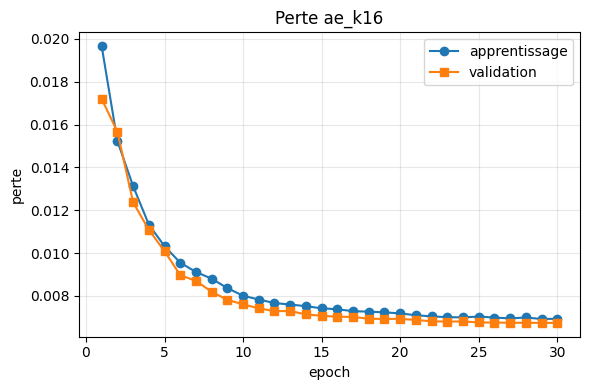

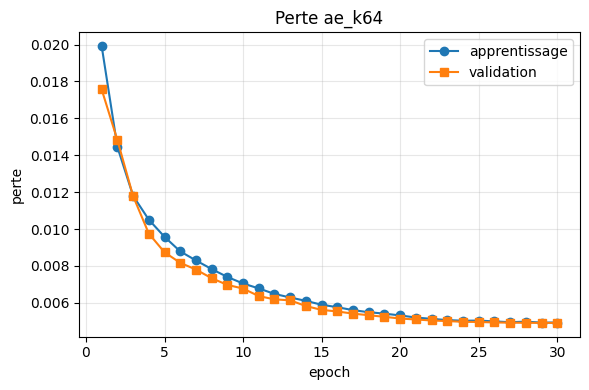

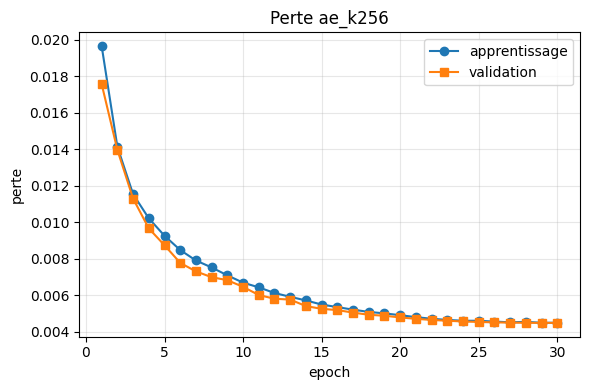

In [4]:
def train_ae(k, noise_std=0.0):
    set_seed(cfg["seed"])
    m = ConvAutoencoder(k)
    tag = f"ae_k{k}" + ("_denoise" if noise_std > 0 else "")
    hp = {"latent_dim": k, "noise_std": noise_std, "epochs": P3["epochs"], "lr": P3["lr"], "batch_size": BS,
          "img_size": SIZE, "loss": "MSE", "train_data": "saines uniquement"}
    exp = OUT / tag
    fit_reconstruction(m, new_train_loader(), val_h_loader, exp, P3["epochs"], P3["lr"], "ae", noise_std,
                       amp=cfg["train"]["amp"], max_minutes=cfg["train"]["max_minutes"],
                       resume=cfg["train"]["resume"], hparams=hp)
    m = load_best(m, exp)
    s_val = reconstruction_scores(m, val_loader)["mse"]   # erreur par image sur TOUTE la validation
    return {"tag": tag, "model": m, "exp": exp, "hp": hp, "val_scores": s_val}

is_h_val = (df_val["label"] == H_IDX).to_numpy()
aes = {}
for k in P3["latent_dims"]:
    aes[f"ae_k{k}"] = train_ae(k)

def val_report(r):
    s = r["val_scores"]
    return {"modèle": r["tag"], "MSE saines (val)": s[is_h_val].mean(), "MSE malades (val)": s[~is_h_val].mean(),
            "AUROC sain/malade (val)": roc_auc_score(~is_h_val, s)}

pd.DataFrame([val_report(r) for r in aes.values()]).round(5)

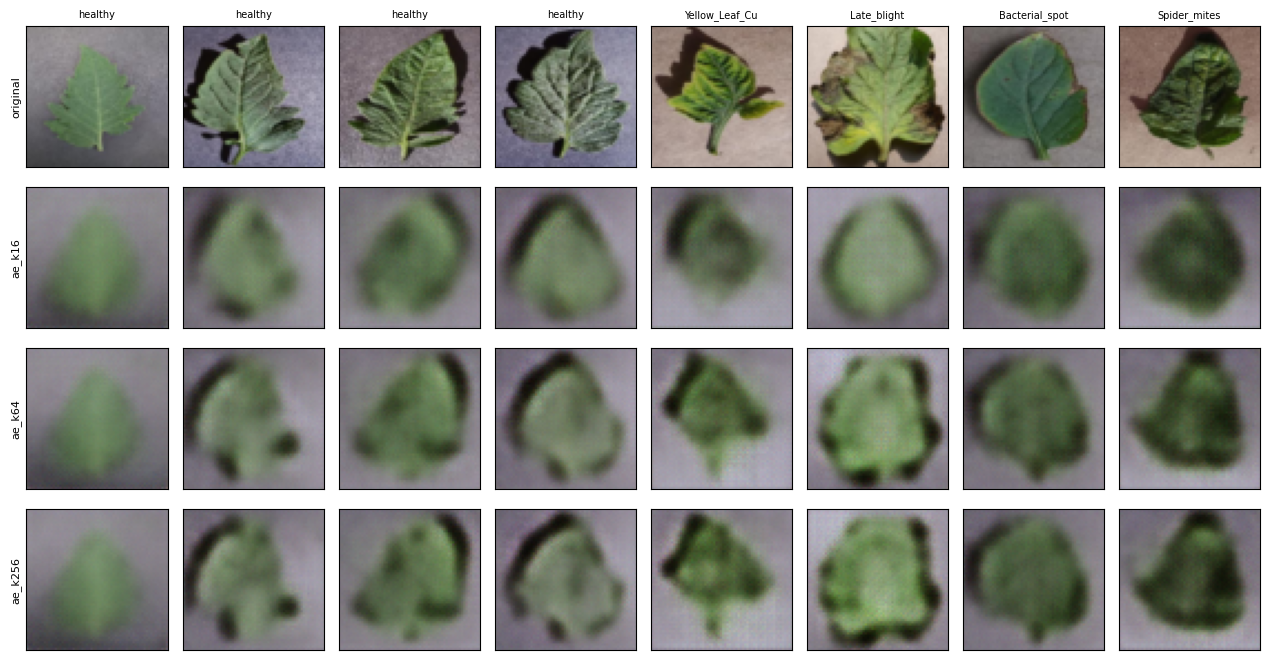

In [5]:
@torch.no_grad()
def show_recon(models: dict, n_h=4, n_d=4, noisy_std=None, fname="recon.png"):
    """Ligne 1 : originaux (saines puis malades) ; lignes suivantes : reconstruction par modèle."""
    rng = np.random.default_rng(cfg["seed"])
    idx = np.r_[rng.choice(np.where(is_h_val)[0], n_h, replace=False), rng.choice(np.where(~is_h_val)[0], n_d, replace=False)]
    x = torch.stack([ds_val[i][0] for i in idx]).to(DEVICE)
    rows, inp = [("original", x)], x
    if noisy_std:   # on montre la capacité de débruitage : les deux modèles reçoivent la même entrée bruitée
        inp = (x + noisy_std * torch.randn_like(x)).clamp(0, 1)
        rows.append(("entrée bruitée", inp))
    for name, m in models.items():
        rows.append((name, m(inp)))
    fig, axes = plt.subplots(len(rows), len(idx), figsize=(1.6 * len(idx), 1.7 * len(rows)))
    for r, (name, imgs) in enumerate(rows):
        for c in range(len(idx)):
            axes[r, c].imshow(imgs[c].permute(1, 2, 0).cpu().clamp(0, 1))
            axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
            if r == 0:
                axes[r, c].set_title(df_val.loc[idx[c], "class_name"][:14], fontsize=7)
        axes[r, 0].set_ylabel(name, fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT / fname, dpi=130)

show_recon({t: r["model"] for t, r in aes.items()}, fname="recon_latent_dims.png")

In [6]:
best_k_tag = max(aes, key=lambda t: val_report(aes[t])["AUROC sain/malade (val)"])
best_k = aes[best_k_tag]["hp"]["latent_dim"]
print("k retenu (validation) :", best_k)

k retenu (validation) : 16


3. Variante débruiteuse

Entrée corrompue $\tilde x = x + \varepsilon$, $\varepsilon \sim \mathcal N(0, \sigma^2)$ avec σ = `noise_std`, **cible propre** x. L'AE ne peut plus se contenter de recopier l'entrée : il doit apprendre la structure d'une feuille saine pour « débruiter ». Intérêt attendu pour la détection : des représentations plus robustes, et une moindre tendance à reconstruire n'importe quoi. L'évaluation se fait sur des images **propres** (comme en déploiement).

Reprise depuis l'epoch 30 (temps déjà écoulé : 5.7 min)


,modèle,MSE saines (val),MSE malades (val),AUROC sain/malade (val)
0,ae_k16,0.00674,0.01022,0.65216
1,ae_k64,0.00491,0.00646,0.60584
2,ae_k256,0.00448,0.00582,0.60088
3,ae_k16_denoise,0.00677,0.01022,0.65379


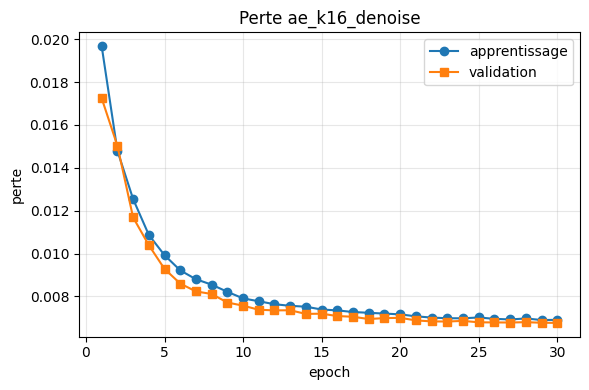

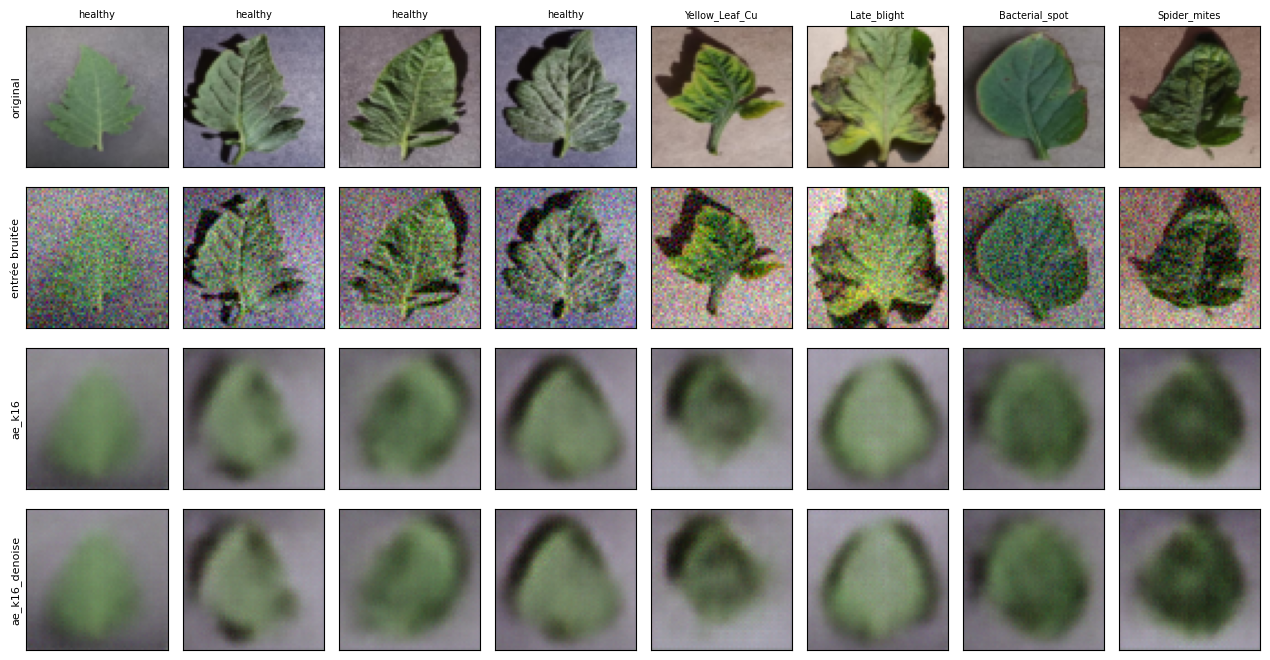

In [7]:
aes[f"ae_k{best_k}_denoise"] = train_ae(best_k, P3["noise_std"])
show_recon({f"ae_k{best_k}": aes[f"ae_k{best_k}"]["model"], f"ae_k{best_k}_denoise": aes[f"ae_k{best_k}_denoise"]["model"]},
           noisy_std=P3["noise_std"], fname="recon_denoising.png")
val_table = pd.DataFrame([val_report(r) for r in aes.values()]).round(5)
val_table.to_csv(OUT / "val_comparison.csv", index=False)
val_table

4. Détection d'anomalies : histogrammes, seuil (validation) puis test

- Choix du modèle final (AE simple ou débruiteur, k retenu) : **AUROC de validation**.
- Seuil : **percentile 95 de l'erreur des feuilles saines de validation** → par construction ~5 % de fausses alarmes attendues.
- Le test n'est utilisé qu'ensuite, une seule fois, pour le modèle final.

Modèle final : ae_k16_denoise | seuil τ = 0.01459 (percentile 95 des saines de validation)


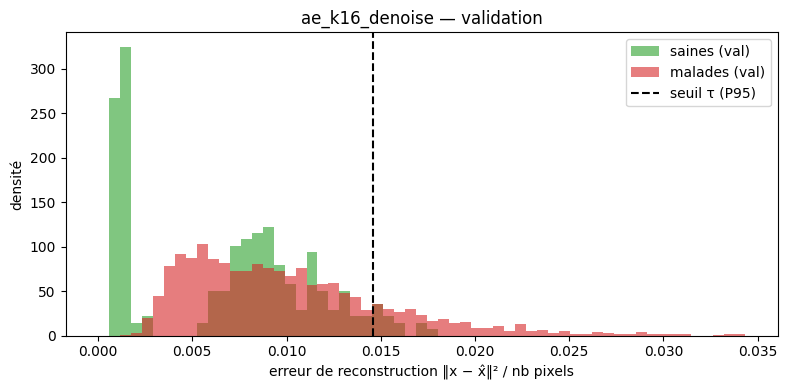

In [8]:
final_tag = max([f"ae_k{best_k}", f"ae_k{best_k}_denoise"], key=lambda t: val_report(aes[t])["AUROC sain/malade (val)"])
fin = aes[final_tag]
s_val = fin["val_scores"]
tau = fit_threshold(s_val[is_h_val], 1 - P3["threshold_percentile"] / 100, split_name="val")
print(f"Modèle final : {final_tag} | seuil τ = {tau:.5f} (percentile {P3['threshold_percentile']} des saines de validation)")

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, np.percentile(s_val, 99.5), 60)
ax.hist(s_val[is_h_val], bins, alpha=0.6, density=True, label="saines (val)", color="tab:green")
ax.hist(s_val[~is_h_val], bins, alpha=0.6, density=True, label="malades (val)", color="tab:red")
ax.axvline(tau, color="k", ls="--", label=f"seuil τ (P{P3['threshold_percentile']})")
ax.set(xlabel="erreur de reconstruction ‖x − x̂‖² / nb pixels", ylabel="densité", title=f"{final_tag} — validation")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "hist_val.png", dpi=150)

[P3_ae_k16_denoise] déjà évalué sur le test : résultat relu depuis test_metrics.json


{'model': 'ae_k16_denoise',
 'auroc': 0.6370700866261885,
 'recall_anomalies': 0.18214716525934863,
 'false_alarm_rate': 0.03765690376569038,
 'threshold': 0.014587224461138248}

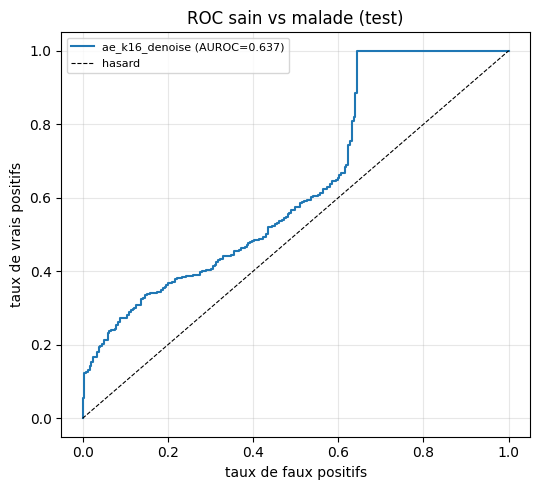

In [9]:
# ===== ÉVALUATION UNIQUE SUR LE TEST (aucun choix après cette cellule) =====
is_h_test = (df_test["label"] == H_IDX).to_numpy()
if f"P3_{final_tag}" in guard.log and (OUT / "test_metrics.json").exists() and not FORCE_TEST_RERUN:
    # Ré-exécution du notebook : le test a déjà servi pour ce modèle -> résultats RELUS, pas recalculés
    print(f"[P3_{final_tag}] déjà évalué sur le test : résultat relu depuis test_metrics.json")
    test_m = load_json(OUT / "test_metrics.json")
    s_test = pd.read_csv(OUT / "test_scores.csv")["score"].to_numpy(np.float32)
else:
    guard.register(f"P3_{final_tag}", force=FORCE_TEST_RERUN)
    s_test = reconstruction_scores(fin["model"], make_loader(ds_test, 256, False, NW))["mse"]
    test_m = anomaly_metrics(s_test[is_h_test], s_test[~is_h_test], tau)
    save_json({"model": final_tag, **test_m}, OUT / "test_metrics.json")
    pd.DataFrame({"class_name": df_test["class_name"], "score": s_test}).to_csv(OUT / "test_scores.csv", index=False)  # réutilisé au nb 05
record_experiment(paths["results"], f"P3_{final_tag}", "3", fin["model"], fin["exp"], SIZE, hparams=fin["hp"],
                  extra_metric="test_auroc / rappel maladies / fausses alarmes",
                  extra_value=f"{test_m['auroc']:.4f} / {test_m['recall_anomalies']:.4f} / {test_m['false_alarm_rate']:.4f}")
for t, r in aes.items():   # autres variantes : résumé sur la VALIDATION seulement
    if t != final_tag:
        record_experiment(paths["results"], f"P3_{t}", "3", r["model"], r["exp"], SIZE, hparams=r["hp"],
                          extra_metric="val_auroc", extra_value=round(val_report(r)["AUROC sain/malade (val)"], 4))
plot_roc({final_tag: (s_test[is_h_test], s_test[~is_h_test])}, OUT / "roc_test.png", "ROC sain vs malade (test)")
test_m

5. Analyse des échecs par maladie

Taux de détection (erreur > τ) et erreur médiane pour chaque classe du test (pour `healthy`, le « taux de détection » est le taux de fausses alarmes).

,n,erreur_mediane,taux_detection
classe,,,
Tomato_mosaic_virus,56,0.0063,0.0000
Bacterial_spot,319,0.0052,0.0031
healthy,239,0.0083,0.0377
Spider_mites,252,0.0091,0.0476
Yellow_Leaf_Curl_Virus,804,0.0097,0.1331
Leaf_Mold,143,0.0102,0.1678
Target_Spot,211,0.0101,0.1801
Early_blight,150,0.0111,0.3533
Septoria_leaf_spot,266,0.0122,0.3534


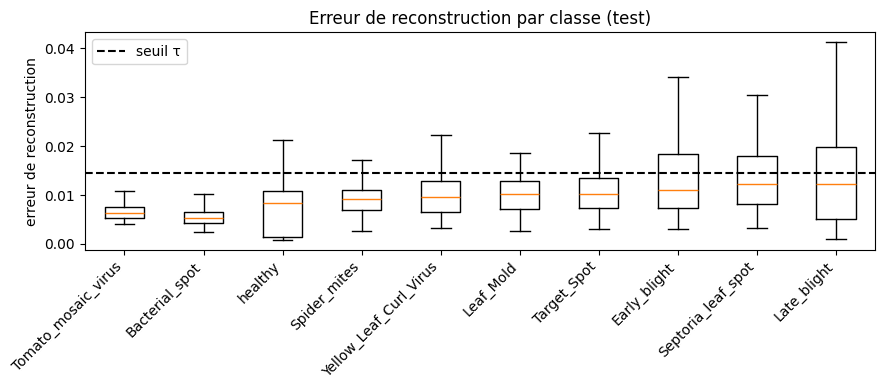

In [10]:
per = (pd.DataFrame({"classe": df_test["class_name"], "erreur": s_test})
         .groupby("classe")["erreur"].agg(n="size", erreur_mediane="median",
                                          taux_detection=lambda e: (e > tau).mean())
         .sort_values("taux_detection"))
per.to_csv(OUT / "per_disease_detection.csv")
display(per.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
order = per.index.tolist()
ax.boxplot([s_test[(df_test["class_name"] == c).to_numpy()] for c in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1), order, rotation=45, ha="right")
ax.axhline(tau, color="k", ls="--", label="seuil τ")
ax.set(ylabel="erreur de reconstruction", title="Erreur de reconstruction par classe (test)")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "per_disease_boxplot.png", dpi=150)

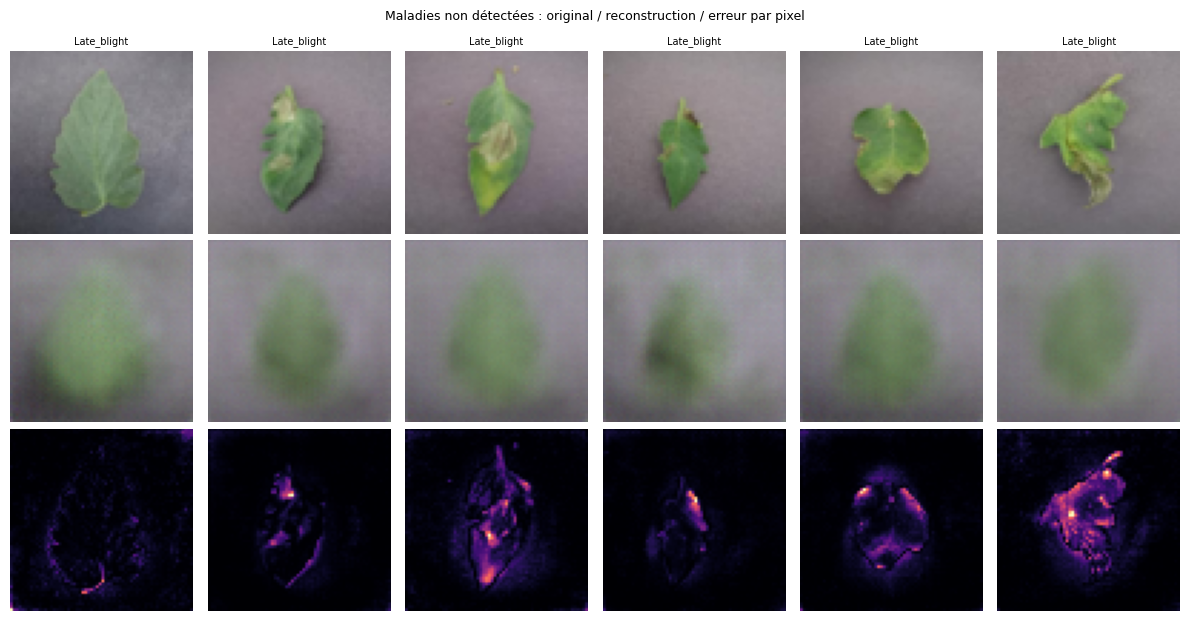

In [11]:
# Pires cas : maladies NON détectées (erreur la plus basse) — original, reconstruction, carte d'erreur
miss = np.where(~is_h_test & (s_test <= tau))[0]
miss = miss[np.argsort(s_test[miss])][:6]
if len(miss):
    fig, axes = plt.subplots(3, len(miss), figsize=(2 * len(miss), 6.3), squeeze=False)
    with torch.no_grad():
        for c, i in enumerate(miss):
            x = ds_test[i][0][None].to(DEVICE)
            xh = fin["model"](x)
            axes[0, c].imshow(x[0].permute(1, 2, 0).cpu())
            axes[0, c].set_title(df_test.loc[i, "class_name"][:14], fontsize=7)
            axes[1, c].imshow(xh[0].permute(1, 2, 0).cpu().clamp(0, 1))
            axes[2, c].imshow(((x - xh) ** 2).mean(1)[0].cpu(), cmap="magma")
    for a in axes.ravel():
        a.axis("off")
    axes[0, 0].set_ylabel("original")
    fig.suptitle("Maladies non détectées : original / reconstruction / erreur par pixel", fontsize=9)
    fig.tight_layout()
    fig.savefig(OUT / "missed_diseases.png", dpi=130)

save_json({"tag": final_tag, "latent_dim": best_k, "denoising": final_tag.endswith("denoise"),
           "exp_dir": str(fin["exp"].relative_to(paths["results"])), "threshold_p95_val": tau}, OUT / "best_ae.json")